# K-Means Clustering with Leakage-Safe Evaluation



This tutorial uses deterministic synthetic data with known labels. The labels are kept out of model fitting and used only for external evaluation. Preprocessing is fit on the training partition, and a shuffled-label baseline shows what chance-level agreement looks like.

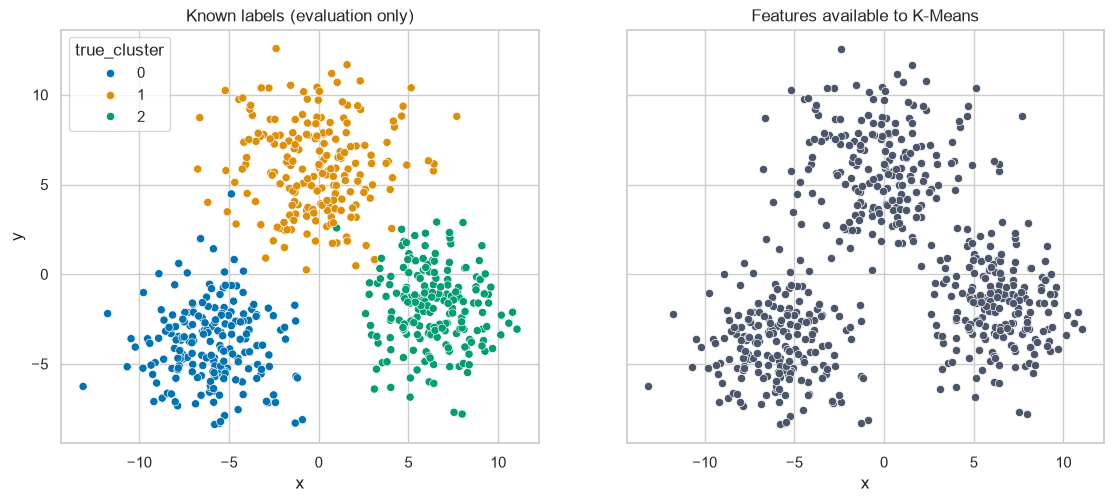

,x,y,true_cluster
0,-5.506997,-3.972297,0
1,5.960724,-0.895020,2
2,-7.800086,0.603252,0
3,7.571600,-1.149085,2
4,-0.622410,8.428927,1


In [1]:
from pathlib import Path



import matplotlib.pyplot as plt

import numpy as np

import pandas as pd

import seaborn as sns

from scipy.optimize import linear_sum_assignment

from sklearn.cluster import KMeans

from sklearn.datasets import make_blobs

from sklearn.metrics import adjusted_rand_score, confusion_matrix, silhouette_score

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler



RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")



features, labels = make_blobs(

    n_samples=600,

    centers=[(-6, -4), (0, 6), (6, -2)],

    cluster_std=[2.2, 2.5, 2.0],

    random_state=RANDOM_STATE,

)

data = pd.DataFrame(features, columns=["x", "y"])

data["true_cluster"] = labels



fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

sns.scatterplot(data=data, x="x", y="y", hue="true_cluster", palette="colorblind", ax=axes[0], s=35)

sns.scatterplot(data=data, x="x", y="y", color="#4c566a", ax=axes[1], s=35)

axes[0].set_title("Known labels (evaluation only)")

axes[1].set_title("Features available to K-Means")

for axis in axes:

    axis.set_aspect("equal", adjustable="box")

plt.tight_layout()

plt.show()



data.head()

## Split first, then fit preprocessing



The true labels stratify the synthetic split so each partition is representative, but they never enter the scaler or K-Means fit. Fitting the scaler on the training features avoids leaking test-set distribution information.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(

    features,

    labels,

    test_size=0.30,

    random_state=RANDOM_STATE,

    stratify=labels,

)



scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)



print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")

print("Training means after scaling:", np.round(X_train_scaled.mean(axis=0), 8))

Training rows: 420; test rows: 180
Training means after scaling: [0. 0.]


## Select $k$ on training data and fit the model



Inertia always decreases as $k$ grows, so it is shown alongside the silhouette coefficient. The known labels are not used to select $k$.

In [3]:
candidate_results = []

for cluster_count in range(2, 7):

    candidate = KMeans(n_clusters=cluster_count, n_init=20, random_state=RANDOM_STATE)

    train_clusters = candidate.fit_predict(X_train_scaled)

    candidate_results.append(

        {

            "k": cluster_count,

            "inertia": candidate.inertia_,

            "silhouette": silhouette_score(X_train_scaled, train_clusters),

        }

    )



selection = pd.DataFrame(candidate_results)

selected_k = int(selection.loc[selection["silhouette"].idxmax(), "k"])

kmeans = KMeans(n_clusters=selected_k, n_init=20, random_state=RANDOM_STATE)

kmeans.fit(X_train_scaled)

print(f"Selected k={selected_k}; converged after {kmeans.n_iter_} iterations")

selection.round(3)

Selected k=3; converged after 4 iterations


,k,inertia,silhouette
0,2,441.713,0.481
1,3,155.642,0.620
2,4,131.731,0.523
3,5,113.578,0.513
4,6,96.418,0.430


## Visualize cluster selection and held-out predictions

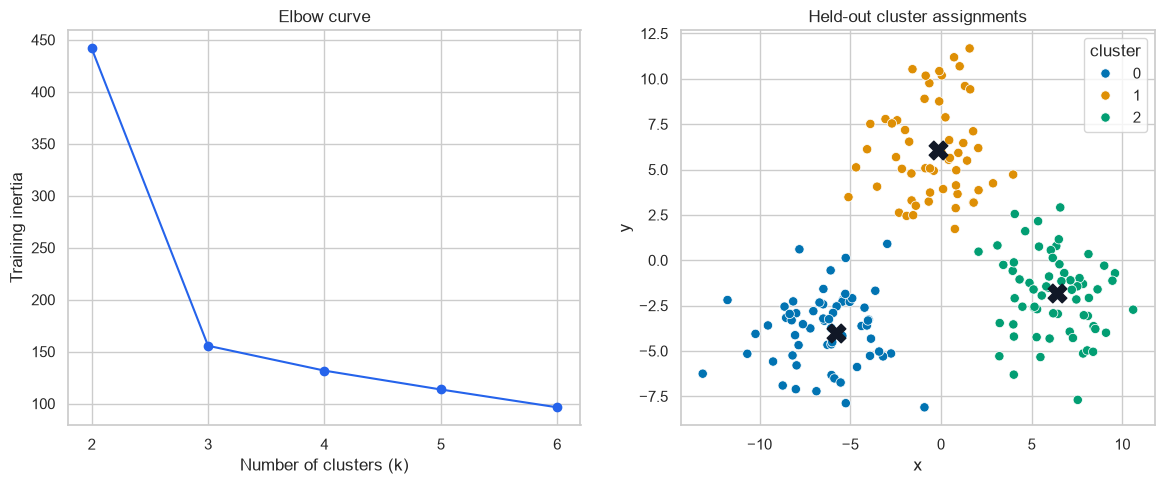

C:\Users\ffollonier\workspace\relataly_new\public\wp-content\uploads\2026\08\041-kmeans-selection-and-test-clusters.png


In [4]:
test_clusters = kmeans.predict(X_test_scaled)

centers = scaler.inverse_transform(kmeans.cluster_centers_)



fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(selection["k"], selection["inertia"], marker="o", color="#2563eb")

axes[0].set(xlabel="Number of clusters (k)", ylabel="Training inertia", title="Elbow curve")

axes[0].set_xticks(selection["k"])



test_plot = pd.DataFrame(X_test, columns=["x", "y"]).assign(cluster=test_clusters)

sns.scatterplot(data=test_plot, x="x", y="y", hue="cluster", palette="colorblind", ax=axes[1], s=45)

axes[1].scatter(centers[:, 0], centers[:, 1], marker="X", s=180, color="#111827", label="centroid")

axes[1].set_title("Held-out cluster assignments")

axes[1].set_aspect("equal", adjustable="box")

plt.tight_layout()



figure_dir = Path(__import__("os").environ.get("RELATALY_FIGURE_DIR", "figures"))

figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "041-kmeans-selection-and-test-clusters.png"

fig.savefig(figure_path, dpi=160, bbox_inches="tight")

plt.show()

print(figure_path)

## Evaluate without assuming cluster numbers are class labels



Adjusted Rand Index (ARI) is invariant to label permutations. For a readable confusion matrix, the Hungarian algorithm finds the one-to-one mapping between predicted cluster IDs and known synthetic labels using only the held-out evaluation table.

In [5]:
contingency = confusion_matrix(y_test, test_clusters)

row_indices, column_indices = linear_sum_assignment(-contingency)

cluster_to_label = dict(zip(column_indices, row_indices))

aligned_predictions = np.array([cluster_to_label[value] for value in test_clusters])



ari = adjusted_rand_score(y_test, test_clusters)

silhouette = silhouette_score(X_test_scaled, test_clusters)

accuracy_after_alignment = np.mean(aligned_predictions == y_test)



pd.Series(

    {"held_out_ARI": ari, "held_out_silhouette": silhouette, "aligned_accuracy": accuracy_after_alignment}

).round(3)

held_out_ARI           0.934
held_out_silhouette    0.631
aligned_accuracy       0.978
dtype: float64

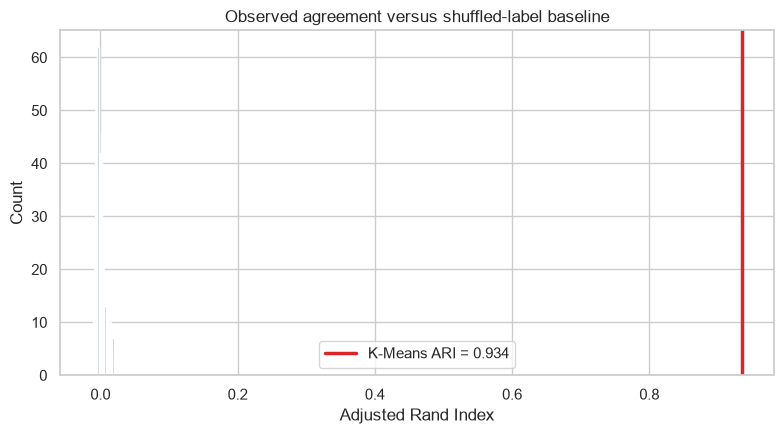

C:\Users\ffollonier\workspace\relataly_new\public\wp-content\uploads\2026\08\041-kmeans-ari-baseline.png


In [6]:
shuffled_ari = np.array(

    [adjusted_rand_score(rng.permutation(y_test), test_clusters) for _ in range(500)]

)



fig, ax = plt.subplots(figsize=(8, 4.5))

sns.histplot(shuffled_ari, bins=25, color="#94a3b8", ax=ax)

ax.axvline(ari, color="#dc2626", linewidth=2.5, label=f"K-Means ARI = {ari:.3f}")

ax.set(xlabel="Adjusted Rand Index", title="Observed agreement versus shuffled-label baseline")

ax.legend()

plt.tight_layout()

figure_path = figure_dir / "041-kmeans-ari-baseline.png"

fig.savefig(figure_path, dpi=160, bbox_inches="tight")

plt.show()

print(figure_path)

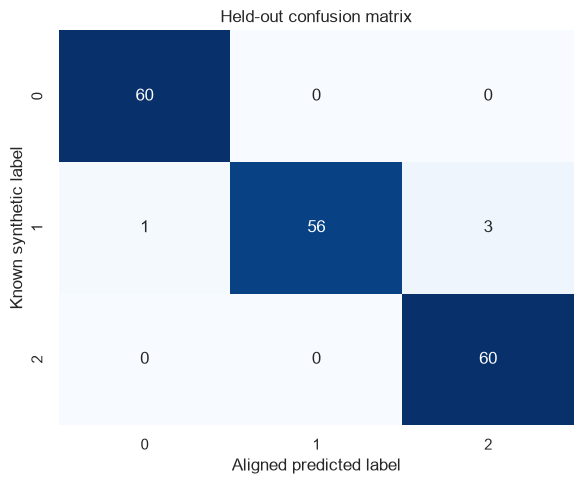

ARI: 0.934
Silhouette: 0.631
Median shuffled-label ARI: -0.001
C:\Users\ffollonier\workspace\relataly_new\public\wp-content\uploads\2026\08\041-kmeans-held-out-confusion-matrix.png


In [7]:
matrix = confusion_matrix(y_test, aligned_predictions)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)

ax.set(xlabel="Aligned predicted label", ylabel="Known synthetic label", title="Held-out confusion matrix")

plt.tight_layout()

figure_path = figure_dir / "041-kmeans-held-out-confusion-matrix.png"

fig.savefig(figure_path, dpi=160, bbox_inches="tight")

plt.show()



print(f"ARI: {ari:.3f}")

print(f"Silhouette: {silhouette:.3f}")

print(f"Median shuffled-label ARI: {np.median(shuffled_ari):.3f}")

print(figure_path)